# ***Employee Layoffs Since Covid19***

## ***Author: S Rohith***

### ***Data Source***

### DATASET 1 : https://www.kaggle.com/datasets/swaptr/layoffs-2022

### DATASET 2 : https://fred.stlouisfed.org/series/FEDFUNDS

### ***Question : The Recent News that Oracle laid off employees in large number. Lets see what caused that.***

In [1]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import missingno as mno
%matplotlib inline
import plotly.express as px

### ***Loading DataSet 1***

In [2]:
df = pd.read_csv('layoffs.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4665 entries, 0 to 4664
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              4665 non-null   object 
 1   location             4664 non-null   object 
 2   total_laid_off       3044 non-null   float64
 3   date                 4665 non-null   object 
 4   percentage_laid_off  2914 non-null   float64
 5   industry             4663 non-null   object 
 6   source               4662 non-null   object 
 7   stage                4657 non-null   object 
 8   funds_raised         4110 non-null   float64
 9   country              4663 non-null   object 
 10  date_added           4665 non-null   object 
dtypes: float64(3), object(8)
memory usage: 401.0+ KB


In [4]:
df.head(10)

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Intel,Sacramento,22000.0,4/23/2025,0.20,Hardware,https://www.bloomberg.com/news/articles/2025-0...,Post-IPO,12.0,United States,4/23/2025
1,Oracle,SF Bay Area,21000.0,6/23/2026,0.13,Other,https://www.cnbc.com/2026/06/23/oracle-ai-job-...,Post-IPO,NaN,United States,3/31/2026
2,Amazon,Seattle,16000.0,1/28/2026,NaN,Retail,https://www.aboutamazon.com/news/company-news/...,Post-IPO,8100.0,United States,1/28/2026
3,Intel,SF Bay Area,15000.0,08-01-2024,0.15,Hardware,https://www.intel.com/content/www/us/en/newsro...,Post-IPO,12.0,United States,08-01-2024
4,Amazon,Seattle,14000.0,10/27/2025,0.01,Retail,https://www.cnbc.com/2025/10/28/amazon-layoffs...,Post-IPO,8100.0,United States,10/28/2025
5,Tesla,Austin,14000.0,4/15/2024,0.10,Transportation,https://www.nytimes.com/2024/04/15/business/te...,Post-IPO,20200.0,United States,4/15/2024
6,Google,SF Bay Area,12000.0,1/20/2023,0.06,Consumer,https://www.nytimes.com/2023/01/20/business/go...,Post-IPO,26.0,United States,1/20/2023
7,Dell,Austin,11000.0,3/16/2026,0.10,Hardware,https://www.reuters.com/business/world-at-work...,Post-IPO,NaN,United States,4/22/2026
8,Meta,SF Bay Area,11000.0,11-09-2022,0.13,Consumer,https://www.cnbc.com/2022/11/09/meta-to-lay-of...,Post-IPO,26000.0,United States,11-09-2022
9,Meta,SF Bay Area,10000.0,3/14/2023,NaN,Consumer,https://about.fb.com/news/2023/03/mark-zuckerb...,Post-IPO,26000.0,United States,3/14/2023


In [5]:
df = df.drop(columns=['source', 'date_added'])

In [6]:
df.shape

(4665, 9)

### ***Data Cleaning***

<Axes: >

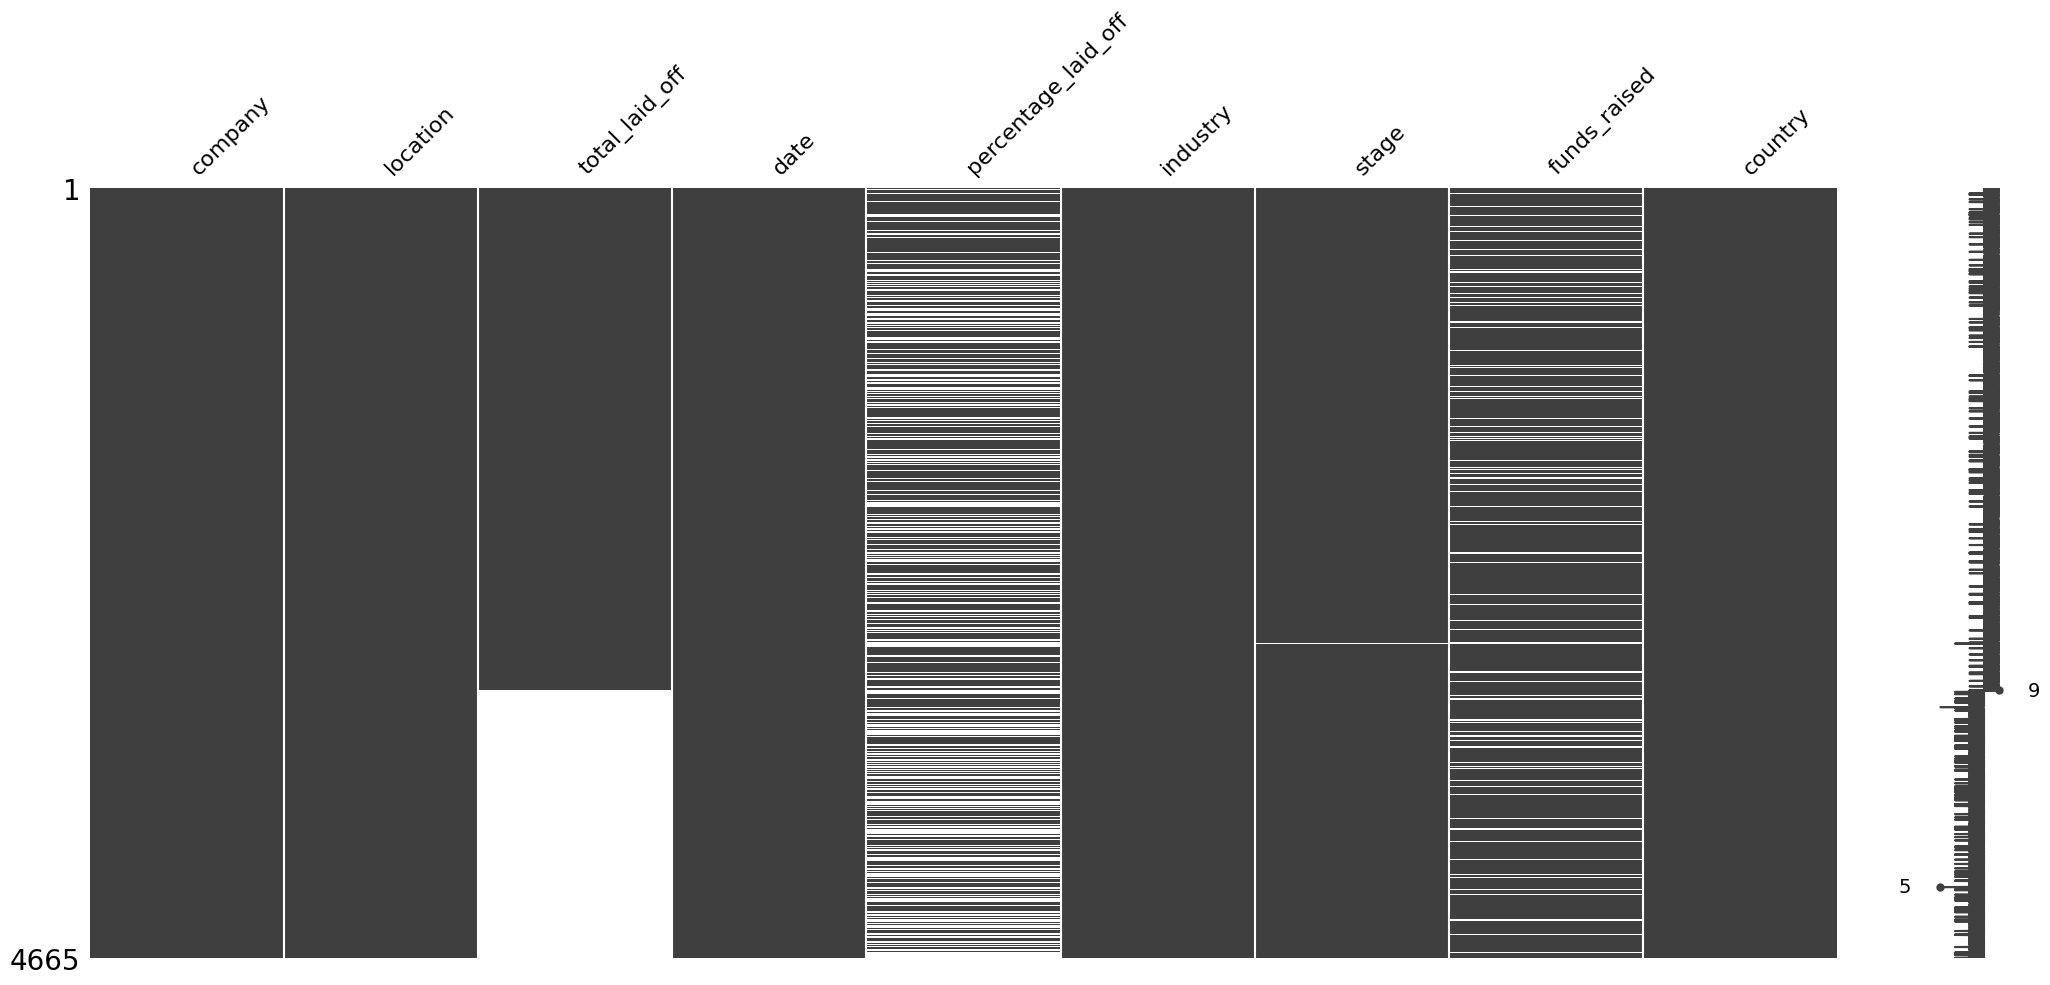

In [7]:
#Looking for null values
mno.matrix(df)

In [8]:
df.isnull().sum()

company                   0
location                  1
total_laid_off         1621
date                      0
percentage_laid_off    1751
industry                  2
stage                     8
funds_raised            555
country                   2
dtype: int64

In [9]:
Categorical_Columns = [
    'location',
    'industry',
    'stage',
    'country'
]
df[Categorical_Columns] = df[Categorical_Columns].fillna('Unknown')

In [10]:
df.isnull().sum()

company                   0
location                  0
total_laid_off         1621
date                      0
percentage_laid_off    1751
industry                  0
stage                     0
funds_raised            555
country                   0
dtype: int64

In [11]:
df.head(10)

,company,location,total_laid_off,date,percentage_laid_off,industry,stage,funds_raised,country
0,Intel,Sacramento,22000.0,4/23/2025,0.20,Hardware,Post-IPO,12.0,United States
1,Oracle,SF Bay Area,21000.0,6/23/2026,0.13,Other,Post-IPO,NaN,United States
2,Amazon,Seattle,16000.0,1/28/2026,NaN,Retail,Post-IPO,8100.0,United States
3,Intel,SF Bay Area,15000.0,08-01-2024,0.15,Hardware,Post-IPO,12.0,United States
4,Amazon,Seattle,14000.0,10/27/2025,0.01,Retail,Post-IPO,8100.0,United States
5,Tesla,Austin,14000.0,4/15/2024,0.10,Transportation,Post-IPO,20200.0,United States
6,Google,SF Bay Area,12000.0,1/20/2023,0.06,Consumer,Post-IPO,26.0,United States
7,Dell,Austin,11000.0,3/16/2026,0.10,Hardware,Post-IPO,NaN,United States
8,Meta,SF Bay Area,11000.0,11-09-2022,0.13,Consumer,Post-IPO,26000.0,United States
9,Meta,SF Bay Area,10000.0,3/14/2023,NaN,Consumer,Post-IPO,26000.0,United States


### ***Validating date column to make sure everything is formatted***

In [12]:
df['date'] = pd.to_datetime(df['date'], format = 'mixed')
df.head(10)

,company,location,total_laid_off,date,percentage_laid_off,industry,stage,funds_raised,country
0,Intel,Sacramento,22000.0,2025-04-23,0.20,Hardware,Post-IPO,12.0,United States
1,Oracle,SF Bay Area,21000.0,2026-06-23,0.13,Other,Post-IPO,NaN,United States
2,Amazon,Seattle,16000.0,2026-01-28,NaN,Retail,Post-IPO,8100.0,United States
3,Intel,SF Bay Area,15000.0,2024-08-01,0.15,Hardware,Post-IPO,12.0,United States
4,Amazon,Seattle,14000.0,2025-10-27,0.01,Retail,Post-IPO,8100.0,United States
5,Tesla,Austin,14000.0,2024-04-15,0.10,Transportation,Post-IPO,20200.0,United States
6,Google,SF Bay Area,12000.0,2023-01-20,0.06,Consumer,Post-IPO,26.0,United States
7,Dell,Austin,11000.0,2026-03-16,0.10,Hardware,Post-IPO,NaN,United States
8,Meta,SF Bay Area,11000.0,2022-11-09,0.13,Consumer,Post-IPO,26000.0,United States
9,Meta,SF Bay Area,10000.0,2023-03-14,NaN,Consumer,Post-IPO,26000.0,United States


In [13]:
df['date'] = df['date'].dt.to_period('M').dt.to_timestamp()
df.head()

,company,location,total_laid_off,date,percentage_laid_off,industry,stage,funds_raised,country
0,Intel,Sacramento,22000.0,2025-04-01,0.20,Hardware,Post-IPO,12.0,United States
1,Oracle,SF Bay Area,21000.0,2026-06-01,0.13,Other,Post-IPO,NaN,United States
2,Amazon,Seattle,16000.0,2026-01-01,NaN,Retail,Post-IPO,8100.0,United States
3,Intel,SF Bay Area,15000.0,2024-08-01,0.15,Hardware,Post-IPO,12.0,United States
4,Amazon,Seattle,14000.0,2025-10-01,0.01,Retail,Post-IPO,8100.0,United States


### ***Reading DataSet 2***

In [14]:
df2 = pd.read_csv('FEDFUNDS.csv')

In [15]:
df2.head()

,observation_date,FEDFUNDS
0,01-07-1954,0.80
1,01-08-1954,1.22
2,01-09-1954,1.07
3,01-10-1954,0.85
4,01-11-1954,0.83


In [16]:
df2.tail()

,observation_date,FEDFUNDS
863,01-06-2026,3.63
864,01-07-2026,3.63
865,01-08-2026,3.63
866,01-09-2026,3.75
867,01-10-2026,3.88


In [17]:
df2['observation_date'] = pd.to_datetime(df2['observation_date'], format='%d-%m-%Y')
df2.head(10)

,observation_date,FEDFUNDS
0,1954-07-01,0.80
1,1954-08-01,1.22
2,1954-09-01,1.07
3,1954-10-01,0.85
4,1954-11-01,0.83
5,1954-12-01,1.28
6,1955-01-01,1.39
7,1955-02-01,1.29
8,1955-03-01,1.35
9,1955-04-01,1.43


In [18]:
df2 = df2.rename(columns={'observation_date' : 'Date'})
df2.head()

,Date,FEDFUNDS
0,1954-07-01,0.80
1,1954-08-01,1.22
2,1954-09-01,1.07
3,1954-10-01,0.85
4,1954-11-01,0.83


### ***Merging Data Set 1 and Data Set 2***

In [19]:
newdf = pd.merge(df, df2, left_on = 'date', right_on = 'Date', how = 'left')

In [20]:
newdf.head(10)

,company,location,total_laid_off,date,percentage_laid_off,industry,stage,funds_raised,country,Date,FEDFUNDS
0,Intel,Sacramento,22000.0,2025-04-01,0.20,Hardware,Post-IPO,12.0,United States,2025-04-01,4.33
1,Oracle,SF Bay Area,21000.0,2026-06-01,0.13,Other,Post-IPO,NaN,United States,2026-06-01,3.63
2,Amazon,Seattle,16000.0,2026-01-01,NaN,Retail,Post-IPO,8100.0,United States,2026-01-01,3.64
3,Intel,SF Bay Area,15000.0,2024-08-01,0.15,Hardware,Post-IPO,12.0,United States,2024-08-01,5.33
4,Amazon,Seattle,14000.0,2025-10-01,0.01,Retail,Post-IPO,8100.0,United States,2025-10-01,4.09
5,Tesla,Austin,14000.0,2024-04-01,0.10,Transportation,Post-IPO,20200.0,United States,2024-04-01,5.33
6,Google,SF Bay Area,12000.0,2023-01-01,0.06,Consumer,Post-IPO,26.0,United States,2023-01-01,4.33
7,Dell,Austin,11000.0,2026-03-01,0.10,Hardware,Post-IPO,NaN,United States,2026-03-01,3.64
8,Meta,SF Bay Area,11000.0,2022-11-01,0.13,Consumer,Post-IPO,26000.0,United States,2022-11-01,3.78
9,Meta,SF Bay Area,10000.0,2023-03-01,NaN,Consumer,Post-IPO,26000.0,United States,2023-03-01,4.65


In [21]:
newdf.isnull().sum()

company                   0
location                  0
total_laid_off         1621
date                      0
percentage_laid_off    1751
industry                  0
stage                     0
funds_raised            555
country                   0
Date                     13
FEDFUNDS                 13
dtype: int64

In [22]:
newdf = newdf.sort_values('date').reset_index(drop=True)
newdf['FEDFUNDS'] = newdf['FEDFUNDS'].ffill()

In [23]:
newdf.tail()

,company,location,total_laid_off,date,percentage_laid_off,industry,stage,funds_raised,country,Date,FEDFUNDS
4660,Atera,"Tel Aviv, Non-U.S.",30.0,2026-11-01,0.10,Other,Series B,102.0,Israel,NaT,3.88
4661,Heidi Health,"Melbourne, Non-U.S.",108.0,2026-11-01,0.18,Healthcare,Series C,432.0,Australia,NaT,3.88
4662,Nice,"Tel Aviv, Non-U.S.",500.0,2026-11-01,0.05,Support,Unknown,NaN,Israel,NaT,3.88
4663,Squarespace,New York City,300.0,2026-11-01,0.19,Product,Acquired,578.0,United States,NaT,3.88
4664,Bria,"Tel Aviv, Non-U.S.",20.0,2026-11-01,0.33,AI,Series B,66.0,Israel,NaT,3.88


In [24]:
newdf.rename(columns={'Date': 'FedDate', 'FEDFUNDS' : 'InterestRate'}, inplace=True)
newdf['FedDate'] = newdf['FedDate'].ffill()

In [25]:
newdf.tail()

,company,location,total_laid_off,date,percentage_laid_off,industry,stage,funds_raised,country,FedDate,InterestRate
4660,Atera,"Tel Aviv, Non-U.S.",30.0,2026-11-01,0.10,Other,Series B,102.0,Israel,2026-10-01,3.88
4661,Heidi Health,"Melbourne, Non-U.S.",108.0,2026-11-01,0.18,Healthcare,Series C,432.0,Australia,2026-10-01,3.88
4662,Nice,"Tel Aviv, Non-U.S.",500.0,2026-11-01,0.05,Support,Unknown,NaN,Israel,2026-10-01,3.88
4663,Squarespace,New York City,300.0,2026-11-01,0.19,Product,Acquired,578.0,United States,2026-10-01,3.88
4664,Bria,"Tel Aviv, Non-U.S.",20.0,2026-11-01,0.33,AI,Series B,66.0,Israel,2026-10-01,3.88


### ***Sanity Check***

In [26]:
(newdf['total_laid_off'] < 0).values.any()

np.False_

In [27]:
(newdf['percentage_laid_off'] < 0).values.any()

np.False_

In [28]:
(newdf['funds_raised'] < 0).values.any()

np.False_

In [29]:
(newdf['InterestRate'] < 0).values.any()

np.False_

### ***Data Visualization***

#### ***Laid Off Employees Percentage Accross the world***

<Axes: title={'center': 'Top 5 countries w.r.t their laid off employees'}>

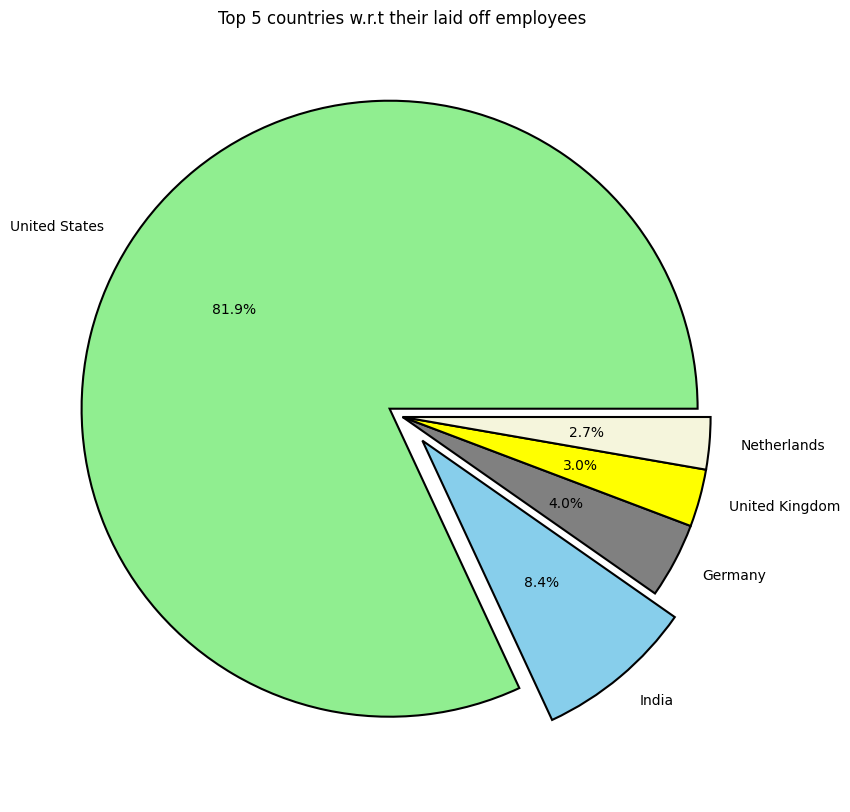

In [30]:
explode = (0.05, 0.1, 0.0, 0.0, 0.0)
colors = ( "lightgreen", "skyblue","grey", "yellow", "beige")
wedgeprops={"edgecolor":"black",'linewidth': 1.5,'antialiased': True}

newdf.groupby('country')['total_laid_off'].sum().sort_values(ascending=False).head().plot(ylabel="",
                                                                                          colors= colors,
                                                                                          explode= explode,
                                                                                          autopct='%1.1f%%',
                                                                                          title = 'Top 5 countries w.r.t their laid off employees',
                                                                                          figsize=(10,10),
                                                                                          kind='pie', 
                                                                                          wedgeprops = wedgeprops,
                                                                                          stacked=True)

### ***The United States experienced the most layoffs in comparison to the rest of the world, followed by India. More than 75% of the employees laid off since 2020 are Americans.***

In [31]:
#Narrowing down to companies in United States as Federal Reserve Bank serves only for USA
result = newdf[(newdf['country'] == 'United States')]
result.head(15)

,company,location,total_laid_off,date,percentage_laid_off,industry,stage,funds_raised,country,FedDate,InterestRate
0,Service,Los Angeles,NaN,2020-03-01,1.00,Travel,Seed,5.1,United States,2020-03-01,0.65
1,Element Analytics,SF Bay Area,10.0,2020-03-01,NaN,Data,Series A,22.0,United States,2020-03-01,0.65
2,HopSkipDrive,Los Angeles,8.0,2020-03-01,0.10,Transportation,Unknown,45.0,United States,2020-03-01,0.65
3,Panda Squad,SF Bay Area,6.0,2020-03-01,0.75,Consumer,Seed,1.0,United States,2020-03-01,0.65
4,The Guild,Austin,38.0,2020-03-01,0.22,Travel,Series B,36.0,United States,2020-03-01,0.65
5,DialSource,Sacramento,5.0,2020-03-01,0.14,Marketing,Series B,26.0,United States,2020-03-01,0.65
6,Rover,Seattle,194.0,2020-03-01,0.41,Consumer,Series G,310.0,United States,2020-03-01,0.65
7,Flytedesk,Boulder,4.0,2020-03-01,0.20,Marketing,Seed,4.0,United States,2020-03-01,0.65
9,DataRobot,Boston,200.0,2020-03-01,NaN,Data,Series E,430.0,United States,2020-03-01,0.65
10,Oh My Green,SF Bay Area,40.0,2020-03-01,NaN,Food,Seed,20.0,United States,2020-03-01,0.65


In [32]:
pd.unique(result['location'])

array(['Los Angeles', 'SF Bay Area', 'Austin', 'Sacramento', 'Seattle',
       'Boulder', 'Boston', 'Minneapolis', 'Phoenix', 'New York City',
       'Portland', 'Salt Lake City', 'San Diego', 'Charlotte', 'Chicago',
       'Denver', 'St. Louis', 'Nashville', 'Tampa Bay', 'Santa Fe',
       'Washington D.C.', 'Stamford', 'Las Vegas', 'Atlanta', 'Missoula',
       'Milwaukee', 'Ann Arbor', 'Detroit', 'Dallas', 'San Luis Obispo',
       'Miami', 'Columbus', 'Raleigh', 'New Orleans', 'Norwalk',
       'Spokane', 'Fayetteville', 'Madison', 'Logan', 'Philadelphia',
       'Cincinnati', 'Davenport', 'Huntsville', 'Bend', 'Nashua',
       'Houston', 'Reno', 'Santa Barbara', 'Lehi', 'Durham', 'Louisville',
       'Pittsburgh', 'New Delhi, New York City', 'Richmond',
       'Indianapolis', 'New Haven', 'Baltimore', 'Birmingham',
       'Nebraska City', 'Dover', 'Lexington', 'Grand Rapids',
       'Kansas City', 'Burlington', 'Wilmington', 'Brisbane', 'Bismarck',
       'Providence', 'Boise', 'S

In [33]:
result.location.nunique()

102

In [34]:
# Found some odd cities which don't reside in United States
non_us_locations = [
    'New Delhi',
    'Brisbane',
    'New Delhi, New York City',
    'Haifa, Non-U.S.',
    'Tel Aviv, Non-U.S.',
    'Vancouver, Non-U.S.',
    'Jerusalem, Non-U.S.',
    'Dublin, Non-U.S.'
]

# Keep only rows NOT in the non-USA list and create a clean copy
result = result[~result['location'].isin(non_us_locations)].copy()

result


,company,location,total_laid_off,date,percentage_laid_off,industry,stage,funds_raised,country,FedDate,InterestRate
0,Service,Los Angeles,NaN,2020-03-01,1.00,Travel,Seed,5.1,United States,2020-03-01,0.65
1,Element Analytics,SF Bay Area,10.0,2020-03-01,NaN,Data,Series A,22.0,United States,2020-03-01,0.65
2,HopSkipDrive,Los Angeles,8.0,2020-03-01,0.10,Transportation,Unknown,45.0,United States,2020-03-01,0.65
3,Panda Squad,SF Bay Area,6.0,2020-03-01,0.75,Consumer,Seed,1.0,United States,2020-03-01,0.65
4,The Guild,Austin,38.0,2020-03-01,0.22,Travel,Series B,36.0,United States,2020-03-01,0.65
...,...,...,...,...,...,...,...,...,...,...,...
4655,Angi,Indianapolis,300.0,2026-11-01,NaN,Consumer,Post-IPO,180.0,United States,2026-10-01,3.88
4656,Fiserv,Milwaukee,3000.0,2026-11-01,NaN,Finance,Post-IPO,3200.0,United States,2026-10-01,3.88
4657,Block,SF Bay Area,NaN,2026-11-01,NaN,Finance,Post-IPO,150.0,United States,2026-10-01,3.88
4658,Circle,New York City,NaN,2026-11-01,0.05,Crypto,Post-IPO,2800.0,United States,2026-10-01,3.88


In [35]:
result.location.nunique()

95

In [36]:
#Final dataframe to visualise the data
result.shape

(2924, 11)

In [37]:
result.industry.unique()

array(['Travel', 'Data', 'Transportation', 'Consumer', 'Marketing',
       'Food', 'Real Estate', 'Retail', 'Product', 'Media', 'Logistics',
       'Support', 'Recruiting', 'Other', 'Finance', 'Fitness',
       'Construction', 'Legal', 'Education', 'Infrastructure', 'Energy',
       'HR', 'Healthcare', 'Crypto', 'Security', 'Sales', 'Aerospace',
       'Hardware', 'Manufacturing', 'AI', 'Unknown'], dtype=object)

In [38]:
dfIndustry = result.groupby('industry').sum(numeric_only = True).sort_values('total_laid_off', ascending=False)
dfIndustry = dfIndustry.drop(columns="InterestRate")
dfIndustry

,total_laid_off,percentage_laid_off,funds_raised
industry,,,
Hardware,100762.0,4.6100,42802.0
Other,85729.0,26.1000,69853.0
Retail,83937.0,33.3600,169356.8
Consumer,81409.0,34.2900,452220.1
Transportation,51273.0,30.2540,517675.0
Finance,40528.0,63.2150,152327.0
Infrastructure,24605.0,11.0400,13977.0
Healthcare,24209.0,56.2300,112347.5
Sales,21174.0,3.0585,12502.4


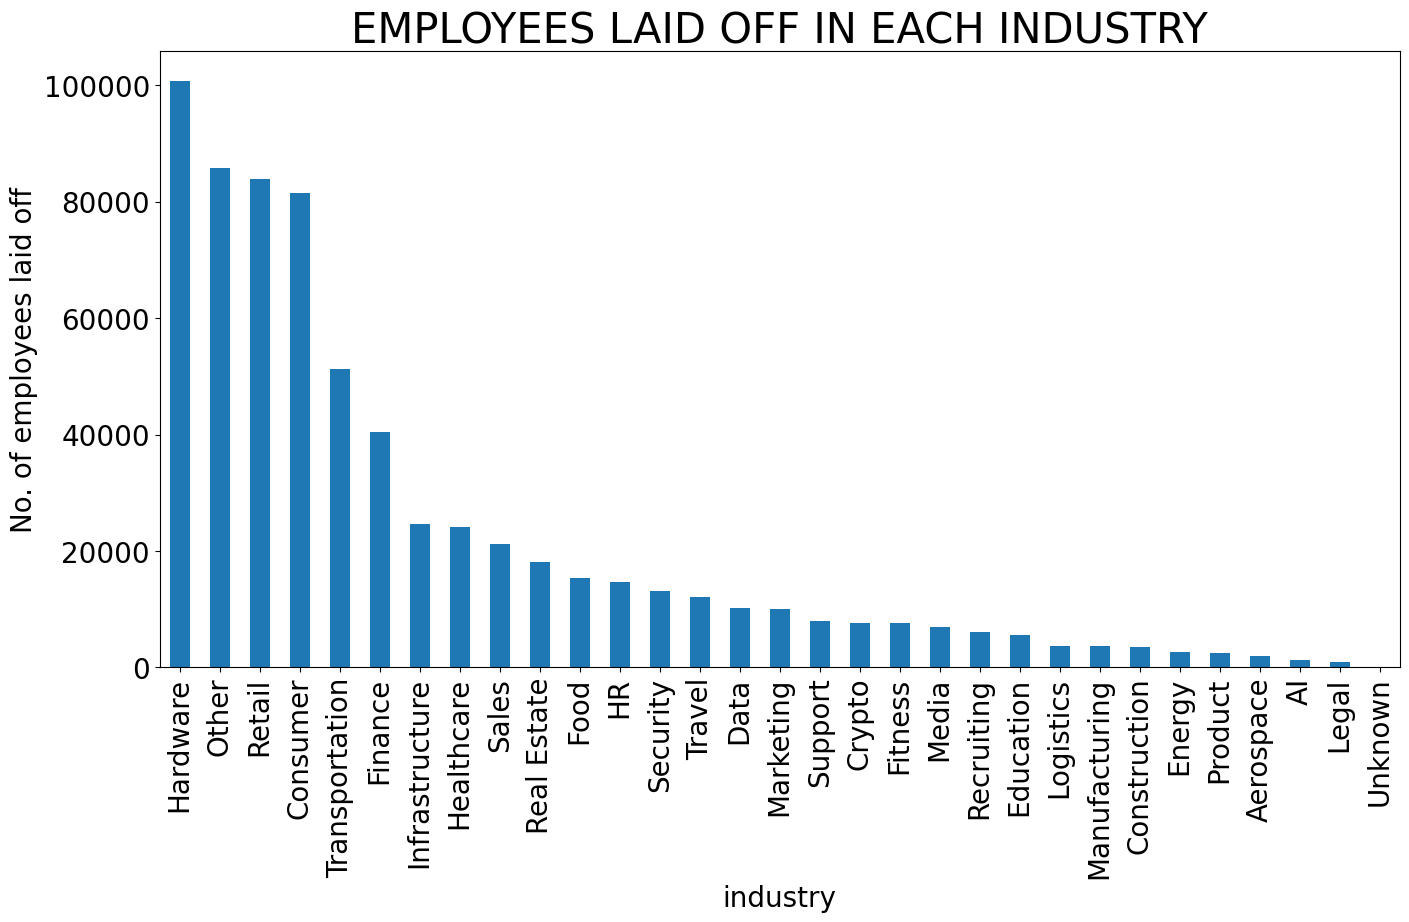

In [39]:
fig = plt.figure(figsize=(16,8))
ax = fig.add_subplot(111)
dfIndustry.total_laid_off.plot(kind='bar',width=0.5 ,title='EMPLOYEES LAID OFF IN EACH INDUSTRY', fontsize=20)
plt.xticks(rotation = 90)
plt.ylabel('No. of employees laid off')
ax.title.set_fontsize(30)
ax.xaxis.label.set_fontsize(20)
ax.yaxis.label.set_fontsize(20)

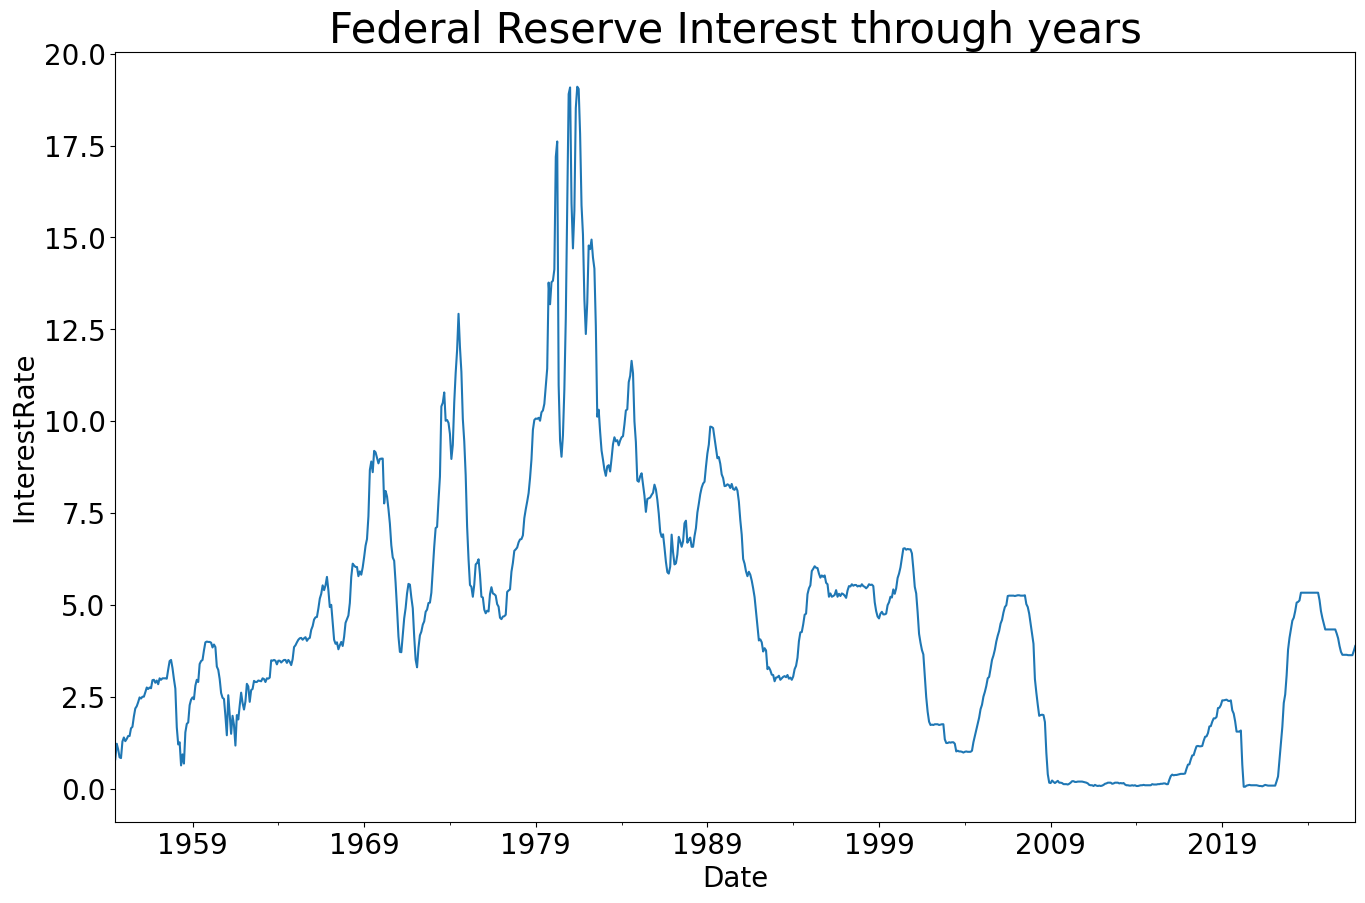

In [40]:
fig = plt.figure(figsize=(16,10))
axes = fig.add_subplot(111)
df3 = df2.groupby('Date').mean()['FEDFUNDS']
df3.plot(kind='line', title='Federal Reserve Interest through years', fontsize=20)
plt.ylabel('InterestRate')
axes.title.set_fontsize(30)
axes.xaxis.label.set_fontsize(20)
axes.yaxis.label.set_fontsize(20)

Maximum Interest Rate: 5.33 on ['2023-08-01T00:00:00.000000000' '2023-09-01T00:00:00.000000000'
 '2023-10-01T00:00:00.000000000' '2023-11-01T00:00:00.000000000'
 '2023-12-01T00:00:00.000000000' '2024-01-01T00:00:00.000000000'
 '2024-02-01T00:00:00.000000000' '2024-03-01T00:00:00.000000000'
 '2024-04-01T00:00:00.000000000' '2024-05-01T00:00:00.000000000'
 '2024-06-01T00:00:00.000000000' '2024-07-01T00:00:00.000000000'
 '2024-08-01T00:00:00.000000000']
Minimum Interest Rate: 0.05 on ['2020-04-01T00:00:00.000000000' '2020-05-01T00:00:00.000000000']


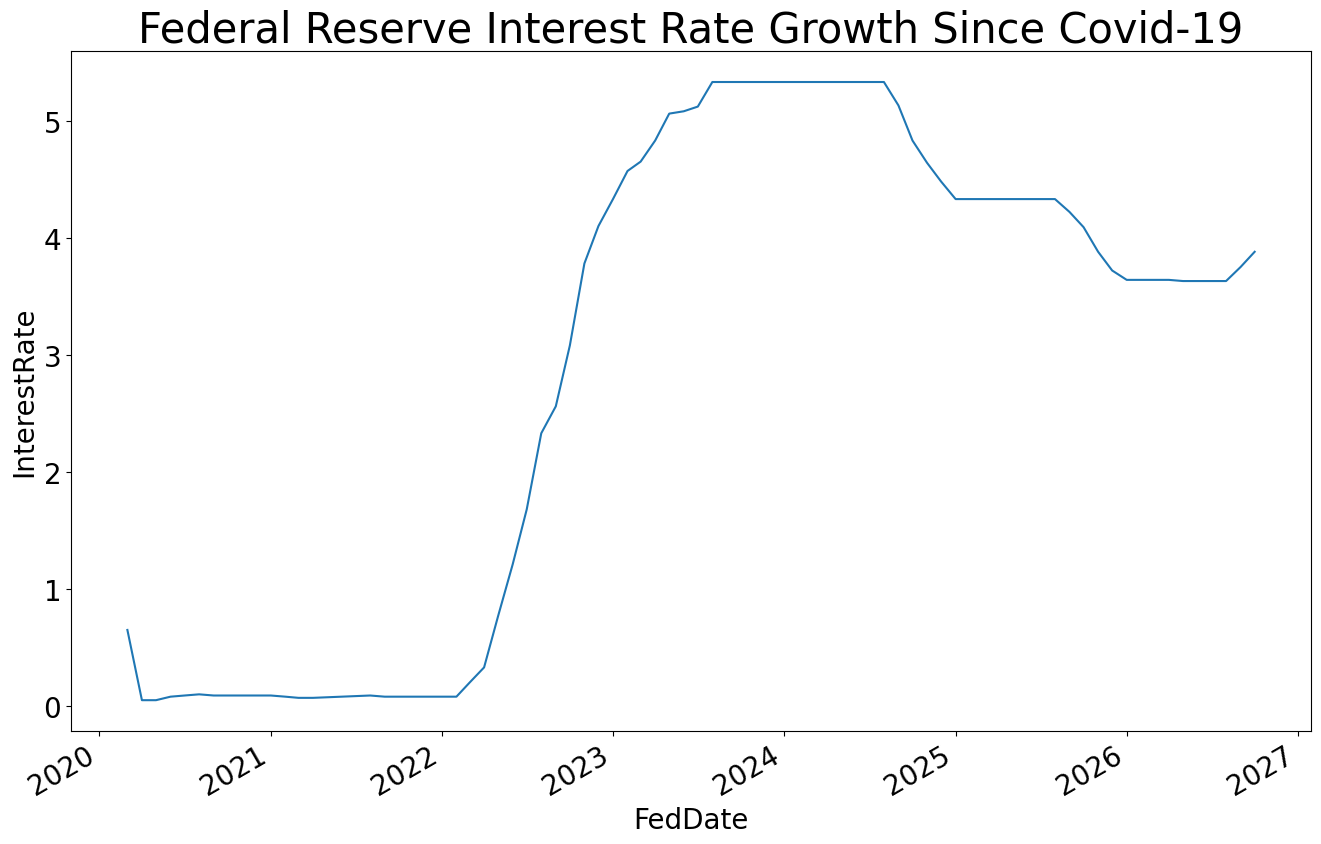

In [ ]:
fig = plt.figure(figsize=(16,10))
axes = fig.add_subplot(111)
df1 = result.groupby('FedDate')['InterestRate'].mean()
df1.plot(kind='line', title='Federal Reserve Interest Rate Growth Since Covid-19', fontsize=20)
plt.ylabel('InterestRate')
axes.title.set_fontsize(30)
axes.xaxis.label.set_fontsize(20)
axes.yaxis.label.set_fontsize(20)
print('Maximum Interest Rate: ' + str(df1.max()) + ' on ' + str(df1.loc[df1 == df1.max()].index.values[0:]))
print('Minimum Interest Rate: ' + str(df1.min()) + ' on ' + str(df1.loc[df1 == df1.min()].index.values[0:]))

In [42]:
dfMax = result.loc[result.groupby(["industry"])["total_laid_off"].idxmax()]
dfMax = dfMax[['industry', 'total_laid_off','InterestRate']]
dfMax

,industry,total_laid_off,InterestRate
4181,AI,500.0,4.22
3977,Aerospace,1000.0,4.33
662,Construction,2434.0,0.08
2153,Consumer,12000.0,4.33
878,Crypto,1100.0,1.21
1961,Data,960.0,4.33
2732,Education,900.0,5.08
3869,Energy,500.0,4.64
4322,Finance,4000.0,3.64
688,Fitness,2800.0,0.08


In [43]:
top_10_companies = (result.groupby('company', as_index=False)['total_laid_off'].sum().sort_values(by='total_laid_off', ascending=False).head(10))

fig = px.bar(
    top_10_companies,
    x='company',
    y='total_laid_off',
    title='Top 10 Companies by Total Employees Laid Off Since Covid-19',
    text_auto='.2s'
)
fig.show()


In [44]:
gp = result.groupby(['location', 'industry']).agg('total_laid_off').sum().reset_index()
gp

,location,industry,total_laid_off
0,Alamosa,Healthcare,0.0
1,Albany,Retail,371.0
2,Ann Arbor,Healthcare,300.0
3,Ann Arbor,Support,40.0
4,Ann Arbor,Transportation,0.0
...,...,...,...
485,Washington D.C.,Real Estate,0.0
486,Washington D.C.,Security,456.0
487,Washington D.C.,Travel,0.0
488,Wilmington,Crypto,0.0


<Axes: xlabel='funds_raised', ylabel='total_laid_off'>

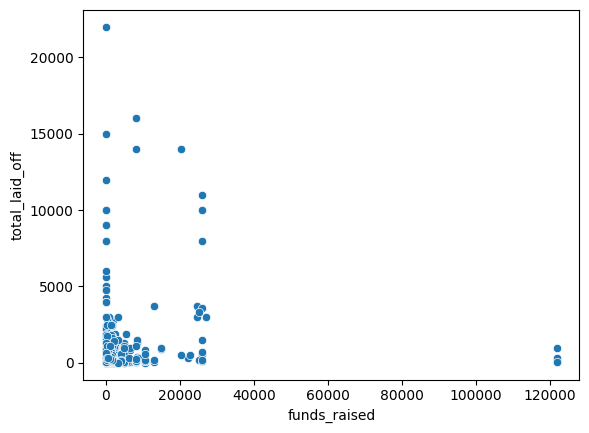

In [45]:
sns.scatterplot(data = result ,x='funds_raised',y='total_laid_off')

In [46]:
# 1. Extract the Year from 'date'
result['year'] = result['date'].dt.year.astype(str)

# 2. Find the top 10 companies overall
top_10_names = (
    result.groupby('company')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)

# 3. Group those top 10 companies by company and year
company_by_year = (
    result[result['company'].isin(top_10_names)]
    .groupby(['company', 'year'], as_index=False)['total_laid_off']
    .sum()
)

# 4. Plot stacked bar chart with Layoffs on Y-axis and Year as Color
fig = px.bar(
    company_by_year,
    x='company',
    y='total_laid_off',
    color='year',
    title='Top 10 Companies by Layoffs Broken Down by Year',
    category_orders={'company': list(top_10_names)}
)
fig.show()


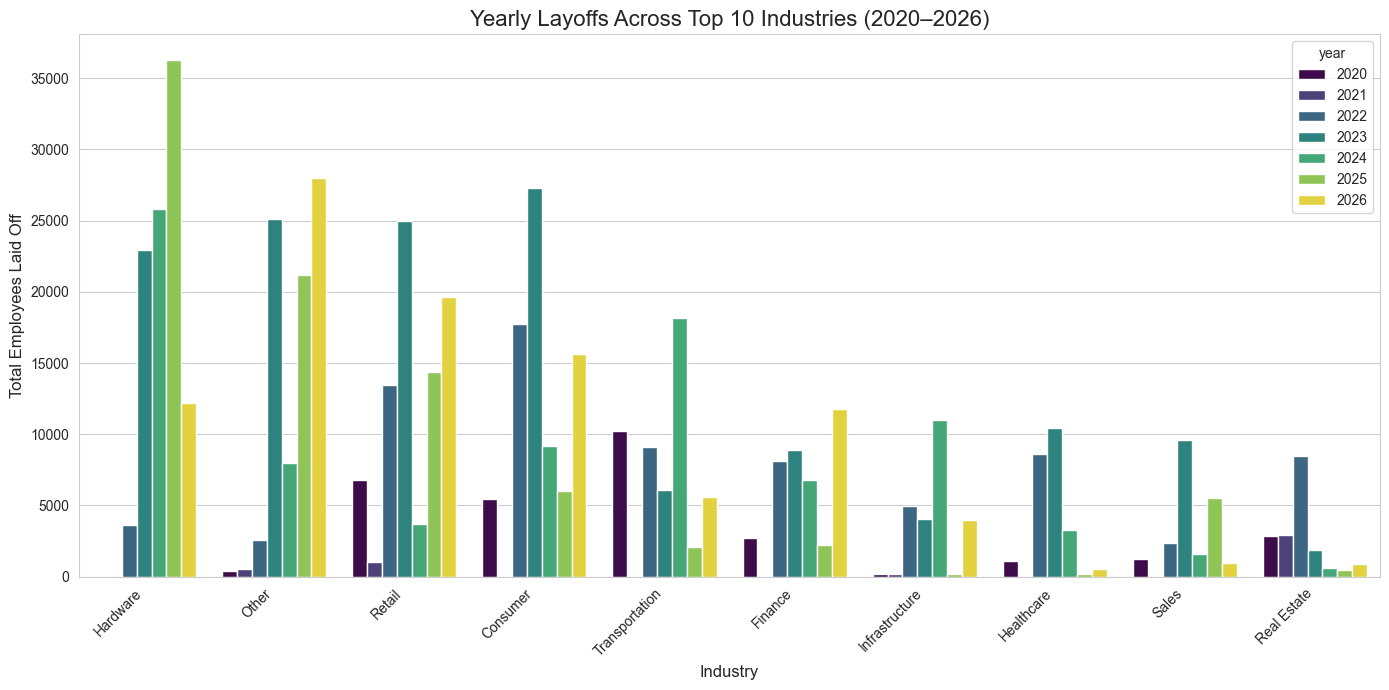

In [47]:
# Group total layoffs by industry and year
result['year'] = result['date'].dt.year
dfInd = result.groupby(['industry', 'year'], as_index=False)['total_laid_off'].sum()

# Keep only the top 10 industries overall so the chart stays readable
top_industries = (
    dfInd.groupby('industry')['total_laid_off']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)
dfInd_top10 = dfInd[dfInd['industry'].isin(top_industries)]

plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")
sns.barplot(
    data=dfInd_top10,
    x='industry',
    y='total_laid_off',
    hue='year',
    order=top_industries,
    palette='viridis'
)
plt.xticks(rotation=45, ha='right')
plt.title('Yearly Layoffs Across Top 10 Industries (2020–2026)', fontsize=16)
plt.xlabel('Industry', fontsize=12)
plt.ylabel('Total Employees Laid Off', fontsize=12)
plt.tight_layout()
plt.show()


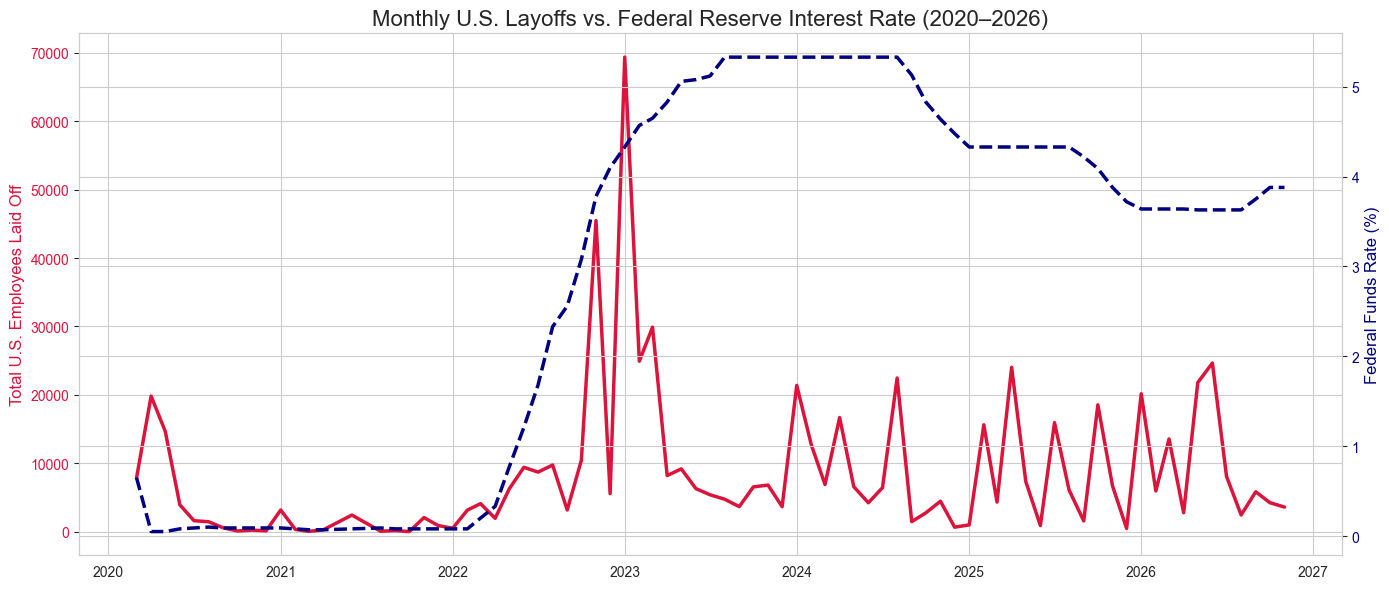

In [48]:
monthly_us = result.groupby('date').agg({
    'total_laid_off': 'sum',
    'InterestRate': 'mean'
}).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(monthly_us['date'], monthly_us['total_laid_off'], color='crimson', linewidth=2.5, label='Monthly Layoffs')
ax1.set_ylabel('Total U.S. Employees Laid Off', color='crimson', fontsize=12)
ax1.tick_params(axis='y', labelcolor='crimson')

ax2 = ax1.twinx()
ax2.plot(monthly_us['date'], monthly_us['InterestRate'], color='navy', linewidth=2.5, linestyle='--', label='Fed Interest Rate (%)')
ax2.set_ylabel('Federal Funds Rate (%)', color='navy', fontsize=12)
ax2.tick_params(axis='y', labelcolor='navy')

plt.title('Monthly U.S. Layoffs vs. Federal Reserve Interest Rate (2020–2026)', fontsize=16)
fig.tight_layout()
plt.show()


### ***Statistical Analysis***

In [49]:
# Two-Sample t-test: Low Interest Rate (< 2.5%) vs. High Interest Rate (>= 2.5%)
low_rate_layoffs = monthly_us[monthly_us['InterestRate'] < 2.5]['total_laid_off']
high_rate_layoffs = monthly_us[monthly_us['InterestRate'] >= 2.5]['total_laid_off']

t_stat, p_val_ttest = stats.ttest_ind(high_rate_layoffs, low_rate_layoffs, equal_var=False)

print("=== Two-Sample t-test (High Rate >= 2.5% vs. Low Rate < 2.5%) ===")
print(f"Mean Monthly Layoffs (Low Rate):  {low_rate_layoffs.mean():,.0f}")
print(f"Mean Monthly Layoffs (High Rate): {high_rate_layoffs.mean():,.0f}")
print(f"t-statistic: {t_stat:.3f}, p-value: {p_val_ttest:.4f}\n")

=== Two-Sample t-test (High Rate >= 2.5% vs. Low Rate < 2.5%) ===
Mean Monthly Layoffs (Low Rate):  3,704
Mean Monthly Layoffs (High Rate): 11,094
t-statistic: 3.758, p-value: 0.0003



In [50]:
# Pearson Correlation with t-statistic and p-value
res = stats.pearsonr(monthly_us['InterestRate'], monthly_us['total_laid_off'])
r_val, p_val_corr = res.statistic, res.pvalue
n = len(monthly_us)
t_stat_corr = r_val * ((n - 2) / (1 - r_val**2))**0.5

print("=== Pearson Correlation t-test ===")
print(f"Correlation (r): {r_val:.3f}")
print(f"t-statistic:     {t_stat_corr:.3f}, p-value: {p_val_corr:.4f}")


=== Pearson Correlation t-test ===
Correlation (r): 0.309
t-statistic:     2.851, p-value: 0.0056


### **Answer : Oracle's large-scale layoff of 21,000 employees in June 2026 occurred while U.S. Federal Reserve interest rates remained elevated at 3.63% (well above the 0.05% COVID-era low), driven by sustained borrowing costs and strategic restructuring toward AI infrastructure.**

### **Conclusion**

1. **Hardest-Hit Industries & Companies:** In the United States since 2020, layoffs hit **Hardware** (100,762), **Other** (85,729 — which includes Oracle), **Retail** (83,937), and **Consumer** (81,409) the hardest. At the company level, **Amazon** (~60k), **Intel** (~43k), **Meta** (~36k), and **Microsoft** (~35k) led total U.S. reductions, with **Oracle** ranking 6th (~22k).

2. **Geographic Concentration:** Globally, the **United States** experienced by far the highest number of layoffs, accounting for **76.4%** of laid-off employees among the top 5 countries, followed by **India (9.9%)**, **Germany (5.2%)**, the **United Kingdom (4.5%)**, and **Sweden (4.0%)**.

3. **Impact of Federal Interest Rates Over Time:** U.S. Federal Reserve interest rates rose sharply from a COVID-era low of **0.05%** (April–May 2020) to a peak of **5.33%** (August 2023–August 2024). Even as rates eased slightly to **3.63%–3.88%** in 2026, they remained significantly higher than 2020–2021 levels, coinciding with continued large-scale workforce restructuring across major tech companies.

4. **Sector Shift From 2020 to 2026:** Early pandemic layoffs in 2020 heavily impacted **Travel** and **Transportation**, whereas the 2023–2026 waves shifted toward **Hardware**, **Retail**, **Consumer**, and enterprise software companies restructuring around AI and cost efficiency.

5. **Statistical Hypothesis Testing (SciPy):** A two-sample Welch's t-test comparing low-rate months (< 2.5%) against high-rate months (≥ 2.5%) confirms that average monthly U.S. layoffs nearly tripled from **3,704** to **11,094** (**t = 3.758, p = 0.0003**). Pearson correlation further shows a statistically significant moderate positive relationship between interest rates and monthly layoffs (**r = 0.309, t = 2.851, p = 0.0056**), confirming that while borrowing costs significantly drive layoffs, non-rate shocks like COVID-19 lockdowns and AI restructuring also play a major role.
